# Comb-content analysis — paper Figures 1–5

The paper's comb-content analysis, organized as the ``combinator.content``
package — one module per figure group (derived from the paper's
``CombContent_Analysis.ipynb``).  This notebook is the executable entry
point: it renders every reproducible panel from package calls.

| Figure | Module | Panels reproduced |
|---|---|---|
| 1 | `seasonality` | C–F (A–B: photograph / segmentation NN, not released) |
| 2 | `celllevel` | A, B, D–G (C: schematic) |
| 3 | `comblevel`, `nestlevel` | A–D (KS p-values for 3B and polarization % for 3C/D have no released code) |
| 4 | `specialization` | B, D–F (A: schematic; C: no released code) |
| 5 | `shuffled` | B–G (A: schematic) |

Every number the paper text quotes for these figures is asserted in
`tests/test_paper_numbers.py`; gaps are documented in
[`RESULTS.md`](RESULTS.md).  Bootstraps are seeded (`np.random.seed(42)`)
so the rendered error bars are stable.

Run from the repository root.  Full render: ~10 min CPU.  To save vector
PDF versions of every panel instead: `uv run python -m
combinator.make_analysis_figures`.


In [1]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 90
np.random.seed(42)

In [2]:
from combinator.content import (celllevel, comblevel, data, nestlevel,
                                seasonality, shuffled, specialization)

tabs = data.load_tables()
masks = data.load_masks(keys=("Contents", "ContentsCrop"))
Contents = masks["Contents"]

print("df_mergedinsp:", tabs["df_mergedinsp"].shape,
      "| px_to_cm:", round(data.px_to_cm(masks["ContentsCrop"]), 4))

df_mergedinsp: (4720, 334) | px_to_cm: 0.4886


## Figure 1 — Seasonality of nest contents (C–F)

Paper claims reproduced exactly (week 10, mean ± 95% CI over the six
control colonies): brood 32.7% ± 7.7%, pollen 8.5% ± 5.5%, nectar &
honey 14.5% ± 3.2%, empty 44.3% ± 8.5%, drone comb 11.7% ± 4.8%.


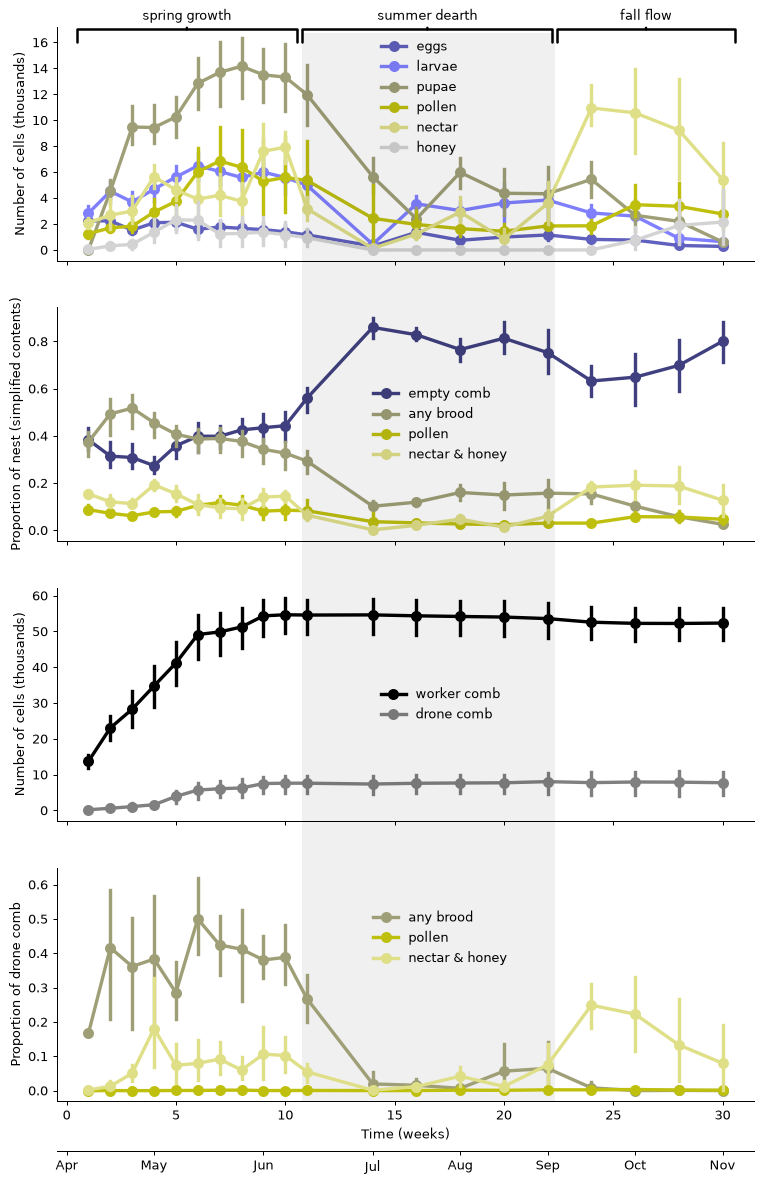

In [3]:
seasonality.figure_1_seasonality(tabs["df_mergedinsp"])
plt.show()

## Figure 2 — Cell-level organization (A, B, D–G)

Cluster metric comes from the committed `df_nearestdist*.csv` tables.
Paper claims: first-10-week cluster metric 0.803 ± 0.145; honey 0.959 ±
0.066; Monte-Carlo significance 7,746/7,765 comb observations, 644/644
nest observations; nest-level metric 0.849 ± 0.097.


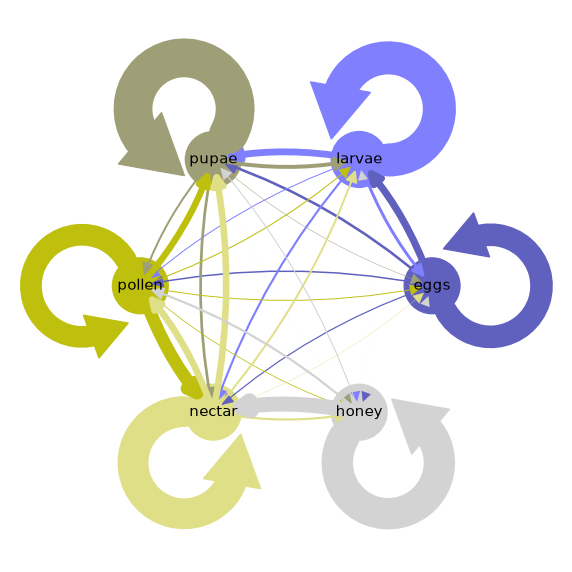

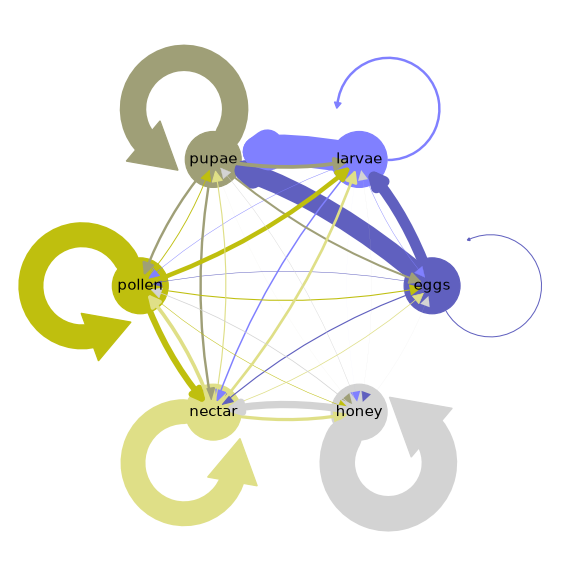

In [4]:
celllevel.neighborhood_network(tabs["df_cellneib"])      # Fig 2A
celllevel.transition_network(tabs["df_cellfuture"])      # Fig 2B
plt.show()

eggs: 0.8217183532042884 (0.7733450070340363 - 0.8493348761289723)
larvae: 0.8264796276965325 (0.7862022822554627 - 0.8527608875110715)
pupae: 0.8157292825093647 (0.7869376245336858 - 0.8366610353164804)
pollen: 0.7554501212032978 (0.7311819353951078 - 0.7798108053844373)
nectar: 0.7143451874459601 (0.6962171848945746 - 0.7337970463613446)
honey: 0.9592499502147162 (0.9508702358127159 - 0.9678623563380891)


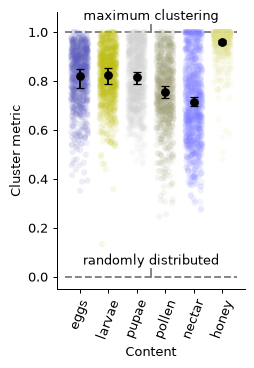

In [5]:
boot = celllevel.bootstrap_cluster_metric(tabs["df_nearestdist"])
celllevel.figure_2_cluster_by_content(tabs["df_nearestdist"], boot)  # Fig 2D
plt.show()

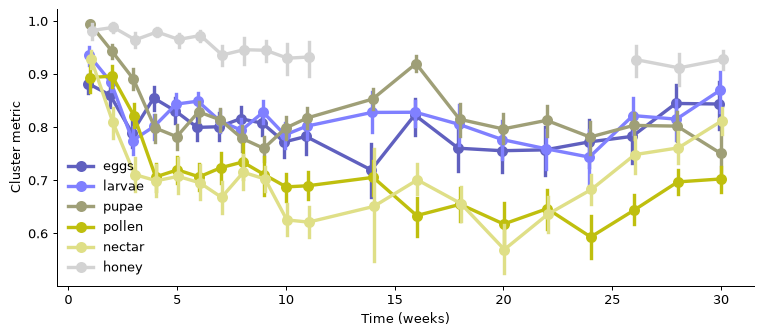

In [6]:
celllevel.figure_2_cluster_over_time(tabs["df_nearestdist"])  # Fig 2E
plt.show()

eggs: 0.8421613154610152 (0.7890547747895112 - 0.8783454002445945)
larvae: 0.8714891465898349 (0.8329335503920331 - 0.8949510134865097)
pupae: 0.8764401839083823 (0.8506646677204325 - 0.8956562549229069)
pollen: 0.8550500051347034 (0.8360365395609847 - 0.8741858062410339)
nectar: 0.7197236619543433 (0.6888303136927861 - 0.753888445650944)
honey: 0.9800123126417686 (0.96972873391308 - 0.9850931188382681)


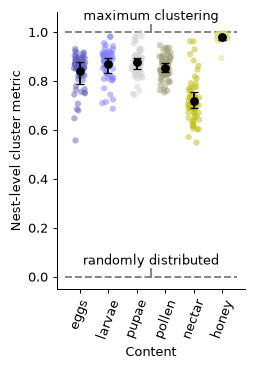

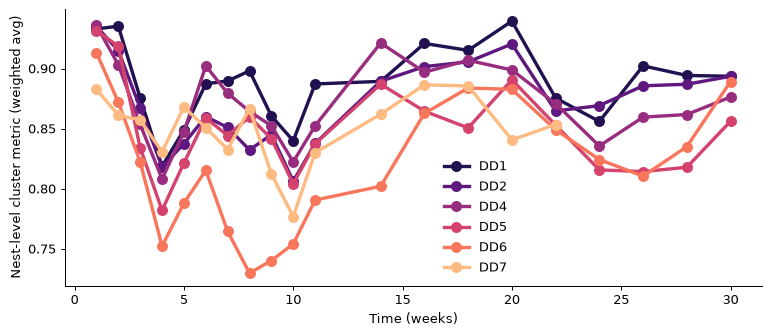

In [7]:
boot_nest = celllevel.bootstrap_cluster_metric(tabs["df_nearestdist_nest"])
celllevel.figure_2_cluster_by_content(
    tabs["df_nearestdist_nest"], boot_nest, jitter=.2, alpha=.5,
    ylabel="Nest-level cluster metric")                                # Fig 2F
celllevel.figure_2_nest_metric_by_colony(
    tabs["df_nearestdist_nest_sum"])                                   # Fig 2G
plt.show()

## Figure 3 — Comb- and nest-level organization (A–D)

PC1/PC2 explain 40%/24% of variance as stated in the paper.  The KS
p-values quoted for 3B and the polarization percentages quoted for 3C/D
have no released code (see `RESULTS.md`); the plotted distributions here
reproduce from the masks.


explained variance: [0.396 0.237 0.141]


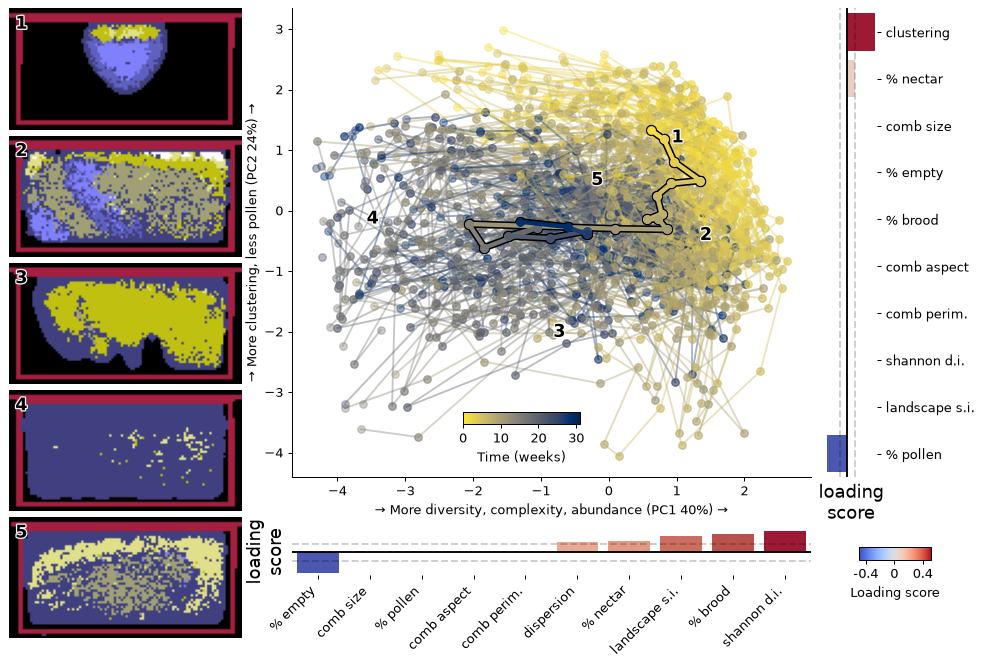

In [8]:
pca, loadings, df_pca, evr = comblevel.comb_pca(tabs["df_mergedinsp"])
print("explained variance:", np.round(evr[:3], 3))
comblevel.figure_3_comb_pca(df_pca, loadings, evr, Contents)  # Fig 3A
plt.show()

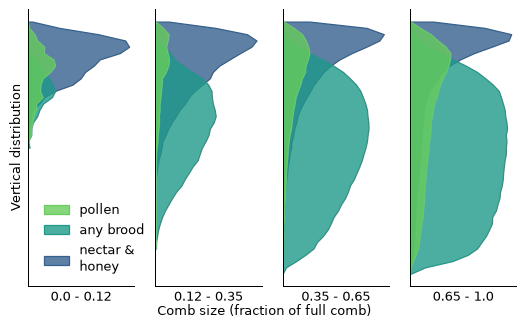

In [9]:
df_coords = comblevel.vertical_distribution_frames(Contents)   # ~15 s
comblevel.figure_3_vertical_distribution(
    df_coords, masks["ContentsCrop"])                                 # Fig 3B
plt.show()

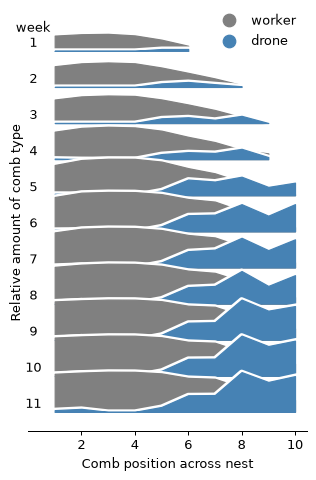

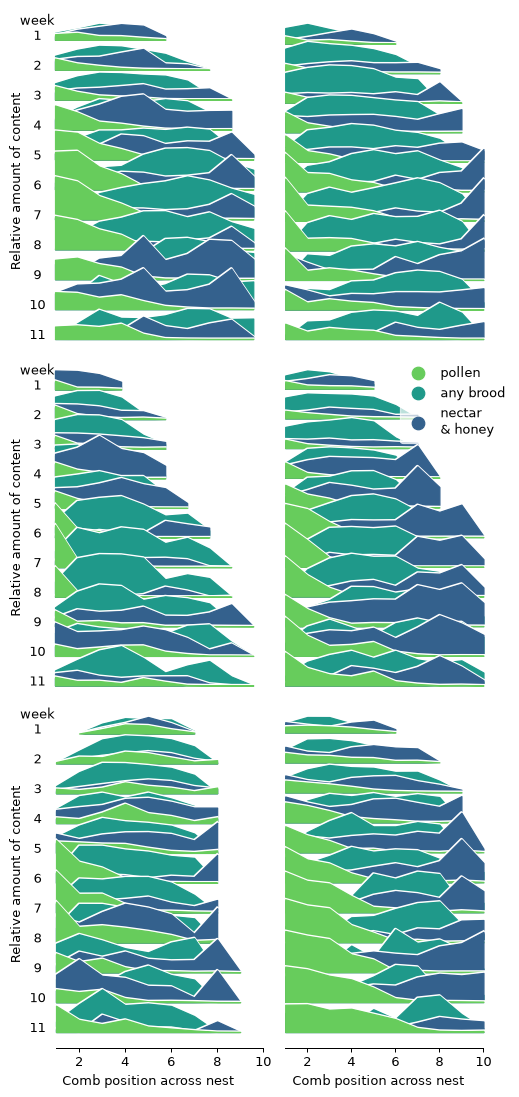

In [10]:
nestlevel.figure_3_combtypes_across_nest(tabs["df_mergedinsp"])  # Fig 3C
nestlevel.figure_3_contents_across_nest(tabs["df_mergedinsp"])      # Fig 3D
plt.show()

## Figure 4 — Specialization (B, D–F)

Cell specialization reproduces the paper exactly: 60.9% ± 3.9% of cells
specialized (thresholds: empty 74.7%, brood 68.5%, pollen 25.0%, nectar
35.2%).  The first cell below is the slow one (~3 min: KDE over every
cell sequence in six nests).


thresholds: empty specialists = 74.72%; brood specialists = 68.48%; pollen specialists = 24.96%; nectar specialists = 35.23%
proportions: generalists = 38.73%; empty specialists = 20.05%; brood specialists = 18.97%; pollen specialists = 11.35%; nectar specialists = 10.9%


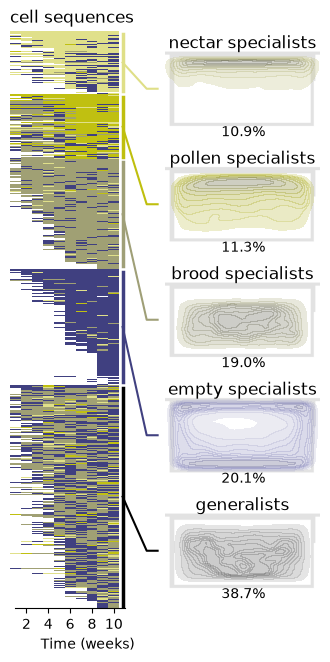

In [11]:
specialization.figure_4_cell_sequences(Contents)               # Fig 4B
plt.show()

/home/jake/projects/honeybee-nest/fork/combinator/content/specialization.py:177: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
ax1.set_yticklabels((ax1.get_yticks()).astype(int), fontsize=8)
/home/jake/projects/honeybee-nest/fork/combinator/content/specialization.py:183: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
ax2.set_xticklabels((ax2.get_xticks()).astype(int), fontsize=8)
/home/jake/projects/honeybee-nest/fork/combinator/content/specialization.py:187: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
ax3.set_xticklabels((ax3.get_xticks()).astype(int), fontsize=8)


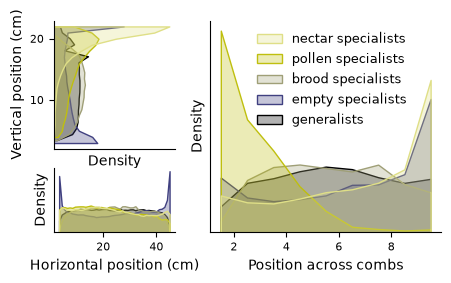

In [12]:
strat = specialization.stratification_sequences(Contents)
specialization.figure_4_stratification(
    strat, Contents, data.px_to_cm(masks["ContentsCrop"]))      # Fig 4D
plt.show()

thresholds: empty specialists = 74.72%; brood specialists = 68.48%; pollen specialists = 24.96%; nectar specialists = 35.23%
proportions: generalists = 38.73%; empty specialists = 20.05%; brood specialists = 18.97%; pollen specialists = 11.35%; nectar specialists = 10.9%


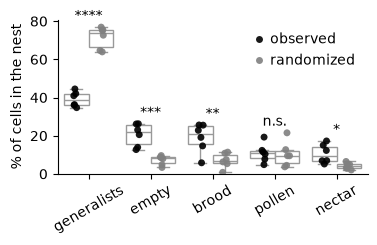

In [13]:
dcp = specialization.cell_specialization_comparison(Contents)
specialization.figure_4_specialization_vs_randomized(dcp)      # Fig 4E
plt.show()

thresholds: empty specialists = 74.72%; brood specialists = 68.48%; pollen specialists = 24.96%; nectar specialists = 35.23%
proportions: generalists = 38.73%; empty specialists = 20.05%; brood specialists = 18.97%; pollen specialists = 11.35%; nectar specialists = 10.9%
comb thresholds: empty specialists = 51.5%; brood specialists = 43.61%; pollen specialists = 30.1%; nectar specialists = 26.48%


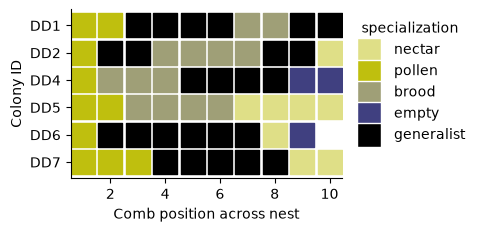

In [14]:
comb_sp = specialization.comb_specialization(Contents)
specialization.figure_4_comb_specialization(comb_sp)           # Fig 4F
plt.show()

## Figure 5 — Disrupting nest organization (B–G)

Paper claims reproduced: bootstrap medians of life-stage totals (eggs
1.83/2.52k, difference 691 vs. text 686.1 ± 510); failed egg/larva
progressions 2,863 ± 488 / 7,260 ± 1,003 (control) and 5,407 ± 1,966 /
8,224 ± 2,256 (shuffled) → 88.9% / 13.3% higher failure; content
fluctuation medians 32.7% vs 47.0% (text 32.7/46.9); comb specialists
34 vs 15 → 55.9% fewer in shuffled nests.


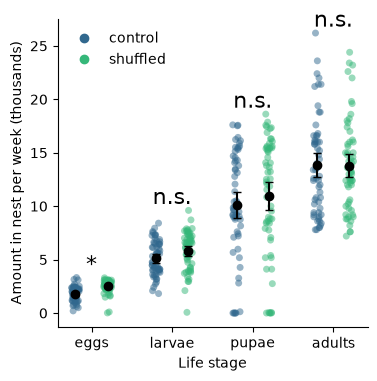

In [15]:
med, err = shuffled.life_stage_bootstraps(tabs["df_mergedinsp"])
shuffled.figure_5_life_stages(tabs["df_mergedinsp"], med, err)  # Fig 5B
plt.show()

/home/jake/projects/honeybee-nest/fork/combinator/content/shuffled.py:210: FutureWarning:
Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.
sns.barplot(ax=axp, data=df, x='treatment', y=df['value'] / 1000,
/home/jake/projects/honeybee-nest/fork/combinator/content/shuffled.py:215: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
axp.set_xticklabels(['cont', 'shuf'])
/home/jake/projects/honeybee-nest/fork/combinator/content/shuffled.py:210: FutureWarning:
Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.
sns.barplot(ax=axp, data=df, x='treatment', y=df['value'] / 1000,
/home/jake/projects/honeybee-nest/fork/combinator/content/shuffled.py:215: UserWa

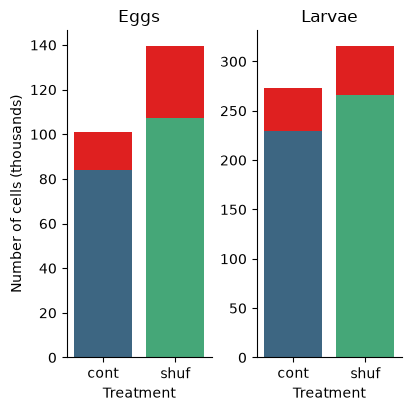

In [16]:
df_broodflow = shuffled.brood_flow(Contents)                    # ~10 s
df_sum = shuffled.brood_flow_summary(shuffled.brood_outcomes(df_broodflow))
shuffled.figure_5_brood_survival(df_sum)                        # Fig 5C
plt.show()

fluctuation bootstrap medians (DD, SH): [np.float64(32.7), np.float64(46.9)]


/home/jake/projects/honeybee-nest/fork/combinator/content/shuffled.py:305: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
ax[1].set_xticklabels(['cont', 'shuf'])


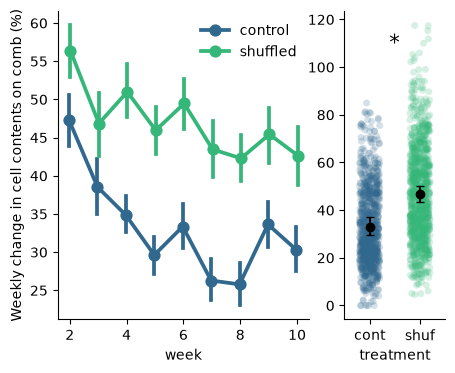

In [17]:
df_changes = shuffled.content_change_frames(tabs["df_mergedinsp"])
_med, err2 = shuffled.content_change_bootstrap(df_changes)
print("fluctuation bootstrap medians (DD, SH):", [round(m, 1) for m in _med])
shuffled.figure_5_content_fluctuations(df_changes, err2)        # Fig 5D
plt.show()

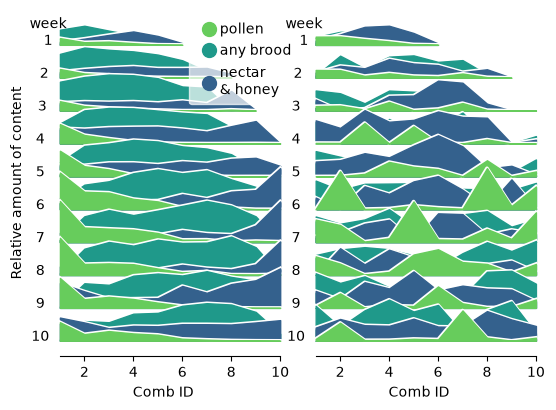

In [18]:
shuffled.figure_5_example_ridgelines(tabs["df_mergedinsp"])    # Fig 5E
plt.show()

thresholds: empty specialists = 74.72%; brood specialists = 68.48%; pollen specialists = 24.96%; nectar specialists = 35.23%
proportions: generalists = 38.73%; empty specialists = 20.05%; brood specialists = 18.97%; pollen specialists = 11.35%; nectar specialists = 10.9%
comb thresholds: empty specialists = 51.5%; brood specialists = 43.61%; pollen specialists = 30.1%; nectar specialists = 26.48%
comb thresholds: empty specialists = 51.5%; brood specialists = 43.61%; pollen specialists = 30.1%; nectar specialists = 26.48%


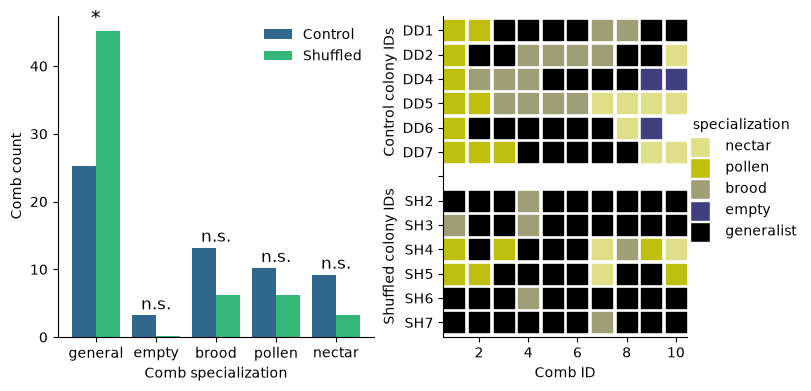

In [19]:
comb_sp_all = shuffled.comb_specialization_all(Contents)
shuffled.figure_5_comb_specialization(comb_sp_all)              # Fig 5F/G
plt.show()

## What this reproduction does **not** contain

- Figure 1A–B: photograph and the segmentation network (not released).
- Figures 2C, 4A, 5A: drawn schematics — no code exists or is needed.
- Figure 3B KS p-values, Figure 3C/D polarization percentages, Figure 4C
  kernel densities and the per-class comb percentages in the text:
  computed offline or with unpublished variants (details:
  [`RESULTS.md`](RESULTS.md)).
- The nest-level cluster tables: their generator needs the unreleased
  `df_mergedlandscape.csv`; the committed tables are canonical.
